# **Module 1: Learn to Drive** 🔧🏎️

---

**Welcome!** This notebook is intended to act as a standalone training guide for running your RoboRacer car autonomously using Reinforcement Learning. We will implement PPO step by step, starting from a car that crashes immediately, and ending with one that completes laps on its own.

No hand-coded rules. No human demonstrations.

---

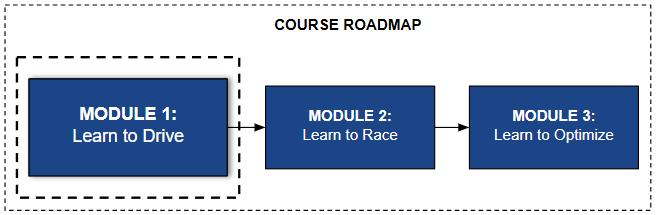

## 📋 Before You Start

### What You Will Learn
- How to frame a robotics problem as an RL problem (observations, actions, rewards)
- How PPO works at an intuitive level
- How to wrap a simulator for RL training
- How to train, monitor, and evaluate a policy

**By the end of this module, we will have trained a policy that enables our car to drive autonomously and complete laps without collision as shown below:**

<p align="center">
  <img src="https://raw.githubusercontent.com/dhyeyshah28/RL_for_Roboracer/main/assets/images/spielbergzoomed.gif" width="330"/>
  <img src="https://raw.githubusercontent.com/dhyeyshah28/RL_for_Roboracer/main/assets/images/RL_levine-crop.gif" width="550"/>
</p>

### What You Need
- A Google account (for Colab)
- **No ROS installation required** — everything runs in this notebook
- **No prior RL experience required** — we explain every concept as we go

### Runtime
- **Training time: ~25–30 minutes** on a Colab T4 GPU
- Make sure you have selected **Runtime → Change runtime type → T4 GPU** before starting

---

> **📌 Note:** This is MODULE 1. We deliberately keep the reward function simple — the car will learn to drive but may be a bit squiggly or slow in places. In MODULE 2 we fix that with reward shaping.

---

## 📝 Student TODOs — Complete These Before Running Training

This notebook has **7 sections** where you must fill in your own implementation.
The rest of the code is provided — but training will not work correctly until
all TODOs are completed.


| # | TODO | Location | What You Build |
|---|---|---|---|
| **TODO 1** | Define the observation space | Section 3 — Wrapper | Observation space bounds |
| **TODO 2** | Normalize the lidar scan | Section 3 — Wrapper | Lidar normalization |
| **TODO 3** | Scale network actions | Section 3 — Wrapper | Action scaling |
| **TODO 4** | Design the reward function | Section 3 — Wrapper `step()` | Reward shaping |
| **TODO 5** | Actor-Critic network forward pass | Section 5 — Network | The policy/value network |
| **TODO 6** | GAE advantage computation | Section 6 — PPO Algorithm | Advantage estimation |
| **TODO 7** | PPO clipped surrogate loss | Section 6 — PPO Algorithm | The core PPO objective |

> **📌 Tip:** Read each section's explanation carefully before filling in its TODO.
> The markdown cells above each code block explain the concept and give you hints.
> You can always refer to the **Section 1 concepts** and **Section 4 reward** explanations
> if you are unsure what values to use.

---



---

# **Section 1 — Concepts**

## 1.1 What Are We Actually Doing?

Before touching any code, let's make sure we understand what Reinforcement Learning means in the context of our race car.

### The RL Loop

At every timestep (100 times per second in our simulator), this loop runs:



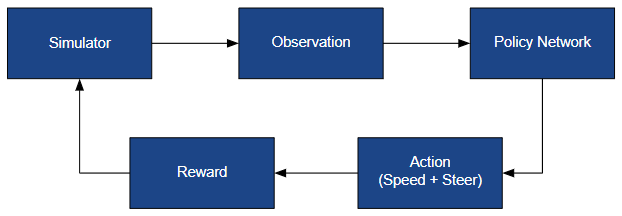



The car sees the world through its sensors (our observation), a neural network decides what to do (our policy), the simulator executes that decision and returns a score (the reward), and the cycle repeats.

Over thousands of laps the network gradually learns which actions lead to higher rewards — without ever being told explicitly how to drive.

### Mapping RL Concepts to Our Car

| RL Concept | What It Means for Our Car |
|---|---|
| **Observation** | 108 lidar beam distances + current speed + current steering angle |
| **Action** | Steering angle and speed command |
| **Reward** | +small for moving forward, −large for crashing |
| **Policy** | A small neural network (2 hidden layers of 64 neurons) |
| **Episode** | One attempt at driving — ends when car crashes or time runs out |

**Why 108 lidar beams?** The car's lidar fires 1080 beams per scan. We keep every 10th beam (108 total) to keep the network small and fast, while still covering the full 270° field of view for this training. We then add the car's current speed and steering angle as a part of the observation space, giving the network the context it needs to decide what to do next. The network never sees the car's global position or the track map. It only ever sees these 110 numbers. We cover this in more detail in Section 3.


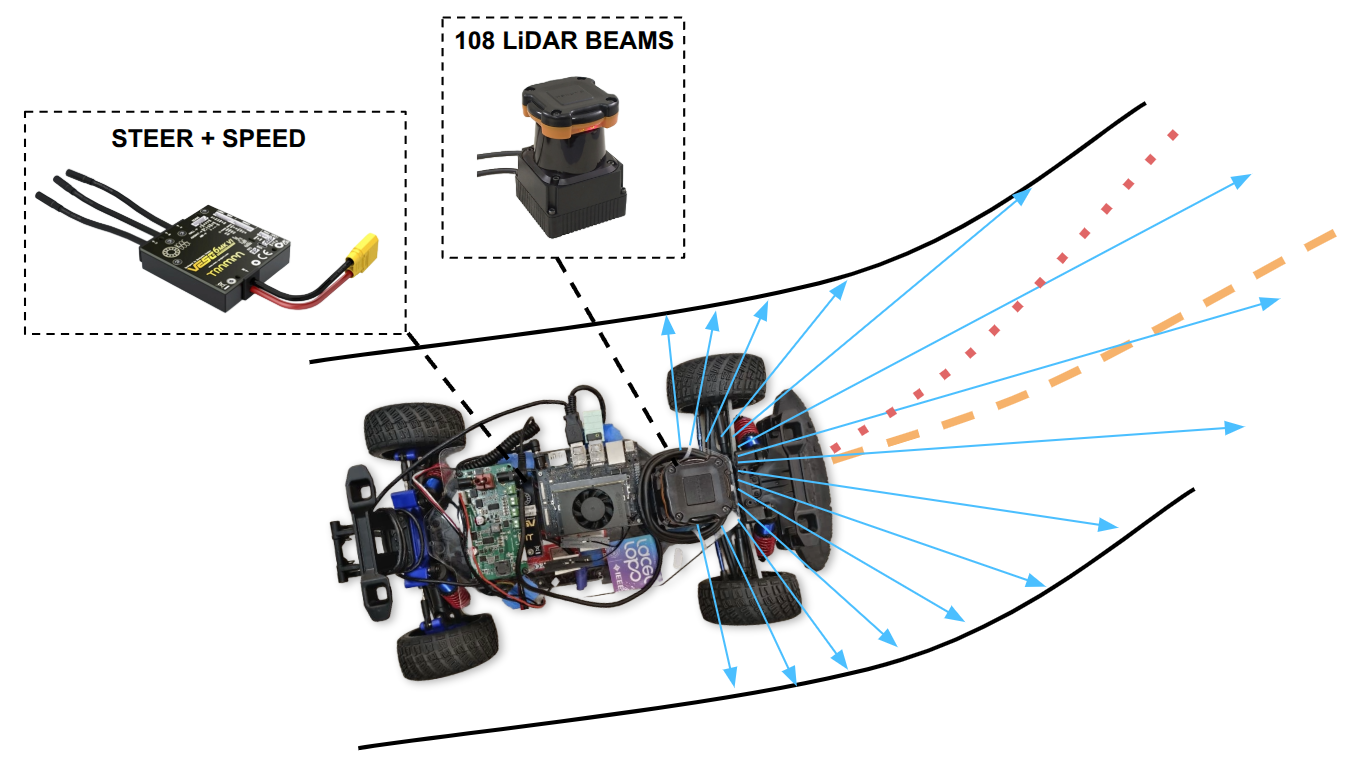



### Why PPO?

PPO (Proximal Policy Optimization) is one of the most reliable RL algorithms for continuous control tasks like driving. It works by:

1. Collecting a batch of experience (the car drives around for a while)
2. Computing how much better or worse each action was than expected (the *advantage*)
3. Updating the policy to do more of the good actions and fewer of the bad ones
4. Repeating — but with a *clip* that prevents any single update from changing the policy too drastically

That last point is the "Proximal" part. Without it, a single bad batch of experience can destroy a policy that took millions of steps to learn. The clip prevents that. We will see this as `clip_range=0.2` in the code, it means the policy is never allowed to change by more than 20% in a single update.

**Now, let's build it.**


---

# **Section 2 — Setup**

## 2.1 Install Dependencies

We need three things:

1. **`f1tenth_gym`** — the physics simulator (the "world" our car lives in)
2. **`stable-baselines3`** — used only for its vectorized environment utilities
   (running multiple simulators in parallel, reward normalization) — **not** for its PPO
   implementation, which we build ourselves in Section 5-7
3. **`wandb`** — for tracking our training metrics in real time

▶️ Run the cell below. It will take about **2–3 minutes** the first time.

In [ ]:
# ── Install all dependencies ──────────────────────────────────────────────────
# f1tenth_gym: the race car simulator (dev-humble branch = latest stable)
!pip install -q git+https://github.com/f1tenth/f1tenth_gym.git@dev-humble

# stable-baselines3: we use only its VecEnv utilities (parallel envs, reward
# normalization) for running rollouts — the PPO algorithm itself is ours
!pip install -q stable-baselines3[extra]

# wandb: experiment tracking — we will log metrics here in real time
!pip install -q wandb

print("Installation complete!")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 257.2/257.2 kB 11.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 953.9/953.9 kB 38.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 104.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 111.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 68.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.0/86.0 MB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 299.9/299.9 kB 28.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.0/51.0 kB 5.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gymnasium>=1.0.0, but you have 

## 2.2 Verify Imports

In [ ]:
# ── Verify everything imports correctly ───────────────────────────────────────
import gymnasium as gym
import numpy as np
import torch
import stable_baselines3
import wandb
import f1tenth_gym

print(f"PyTorch:          {torch.__version__}")
print(f"CUDA available:   {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU:              {torch.cuda.get_device_name(0)}")
print(f"Stable Baselines: {stable_baselines3.__version__}")
print(f"Gymnasium:        {gym.__version__}")
print()
print("All good — let's start training!")

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


PyTorch:          2.11.0+cu128
CUDA available:   True
GPU:              Tesla T4
Stable Baselines: 2.9.0
Gymnasium:        0.29.1

All good — let's start training!


## 2.3 Pre-Cache the Track Map

> The first time a track is loaded, the gym downloads and extracts it. If multiple parallel environments try to do this simultaneously they can conflict. We pre-cache it here (once, single-threaded) to avoid that race condition.

Here we are selecting the Spielberg Map, but you can select your own map files to train your car on the appropriate race track.

In [ ]:
# ── Pre-cache the track map ───────────────────────────────────────────────────
from f1tenth_gym.envs.track import Track
Track.from_track_name('Spielberg')
print("Spielberg track cached — ready to train!")

Extracting Files for: Spielberg
Spielberg track cached — ready to train!


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---

# **Section 3 — The Environment**
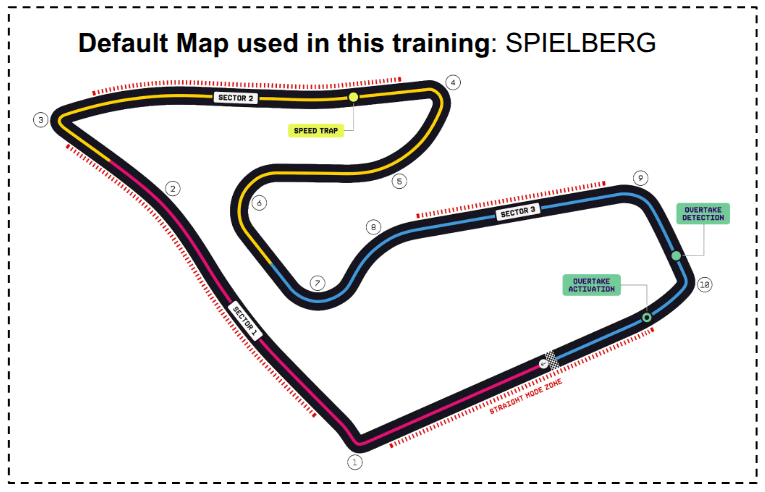

## 3.1 The Simulator Wrapper

The F1TENTH gym returns observations as a nested dictionary:

```python
{
  "agent_0": {
    "scan":      [...],   # 1080 lidar beams (distances in metres)
    "std_state": [...],   # [x, y, steering_angle, speed, heading, yaw_rate, slip_angle]
    "collision": False    # True if car is touching a wall this step
  }
}
```

RL algorithms like PPO expect a **flat numpy array**, a single list of numbers, not a nested dictionary. Our `F1TenthRLWrapper` class bridges this gap. Think of it as a translator sitting between the simulator and the learning algorithm.

### What the Wrapper Does

| Step | What Happens | Why |
|---|---|---|
| **1. Extract** | Pulls lidar scan and `std_state` from the nested dict | PPO can't read nested dicts, it needs a flat array |
| **2. Downsample lidar** | 1080 beams → 108 beams (every 10th reading) | Smaller input = smaller faster network. 108 beams still gives full 270° coverage, enough to detect walls, gaps, and corners |
| **3. Normalize** | All values scaled to [0, 1] | Neural networks train much faster when all inputs are on the same scale. |
| **4. Add speed + steer** | Appends 2 numbers to obs → 110-dim total | The car gets context about how fast it's actually going and how much it's already steering to make better informed decisions. |
| **5. Scale actions** | Network outputs [-1, 1] → physical steer (rad) + speed (m/s) | The network always outputs numbers in [-1, 1]. We map those to physical limits: steering ±0.4189 rad, speed 1.5–6.0 m/s |
| **6. Compute reward** | Calculates the reward signal each step | This is the score the car gets each step, it drives the learning. Covered in Section 4. |

### What the Observation Looks Like

```
obs = [lidar_0, lidar_1, ..., lidar_107,  speed_norm,  steer_norm]
       ←-------- 108 values -----------►  ←--- 1 ---►  ←--- 1 ---►
       all normalized to [0, 1]                        total: 110

lidar value = 0.0  → wall is right there (0 m away)
lidar value = 1.0  → open space, nothing within 10 m
speed value = 1.0  → car is at max speed (6 m/s)
speed value = 0.0  → car is stationary
```

> **Note:** `std_state[0]` and `std_state[1]` are the car's global x, y position. We use these only to compute the progress reward — they are **never part of the observation the network sees**. The policy works purely from sensor readings, which means it runs identically on the real car without any localization or GPS.

Read through the class below, every important line has a comment explaining *why* it is there.

*(This is not the main training block.)*


In [ ]:
class F1TenthRLWrapper(gym.Env):
    """
    Wraps the F1TENTH gym into a standard RL environment.

    Observation (110-dim, all values in [0, 1]):
        [0:108]  108 lidar beam distances, normalized to [0, 1]
        [108]    current speed, normalized by max_speed
        [109]    current steering angle, normalized to [0, 1]

    Action (2-dim, values in [-1, 1]):
        [0]  steering command  → scaled to gym physical limits (rad)
        [1]  speed command     → scaled to [min_speed, max_speed] m/s

    Reward (Learn to Drive — simple):
        +delta_progress * 10   forward progress along the track
        +0.03 * (speed/vmax)   small speed bonus (prevents crawling)
        -30.0                  crash penalty (episode ends)

    Gym simplifications used:
        LiDARConfig(num_beams, range_max)  — gym handles downsample + 10m clip
        frenet_pose[0] / track_length      — gym frenet s for O(1) progress
        env.action_space.high[0][0]        — max_steer read from gym directly
        max_speed = 6.0 hardcoded          — gym returns 20.0 physical max, we cap
    """

    def __init__(self, map_name="Spielberg", num_beams=108, render_mode=None):
        super().__init__()

        # ── Import gym internals ──────────────────────────────────────────────
        from f1tenth_gym.envs.env_config import (
            EnvConfig, SimulationConfig, ObservationConfig, ResetConfig,
        )
        from f1tenth_gym.envs.lidar.config import LiDARConfig
        from f1tenth_gym.envs.observation import ObservationType
        from f1tenth_gym.envs.reset import ResetStrategy
        from f1tenth_gym.envs.integrators import IntegratorType
        from f1tenth_gym.envs.dynamic_models import DynamicModel

        # ── Configure the simulator ───────────────────────────────────────────
        env_config = EnvConfig(
            map_name=map_name,
            num_agents=1,
            simulation_config=SimulationConfig(
                timestep=0.01,                  # 100 Hz — matches real F1TENTH car
                integrator=IntegratorType.RK4,  # Runge-Kutta 4th order
                dynamics_model=DynamicModel.ST, # Single-Track: includes tire slip
                max_laps=5,
            ),
            observation_config=ObservationConfig(type=ObservationType.DIRECT),
            # LiDARConfig: gym handles downsample to 108 beams + clips at 10m
            # removes need for manual np.linspace and np.clip in _process_obs
            lidar_config=LiDARConfig(
                num_beams=num_beams,  # gym fires exactly 108 beams — no downsampling needed
                range_max=10.0,       # gym clips at 10m
                noise_std=0.0,        # clean training — no sensor noise
            ),
            reset_config=ResetConfig(
                strategy=ResetStrategy.RL_RANDOM_STATIC
            ),
            render_enabled=(render_mode is not None),
        )

        self.env = gym.make(
            "f1tenth_gym:f1tenth-v0",
            config=env_config,
            render_mode=render_mode,
        )

        # ── Physical limits — read from gym action space, not hardcoded ───────
        # gym exposes the actual physical limits of the car directly
        # avoids hardcoding values that may differ across car configs

        self.max_steer  = float(self.env.action_space.high[0][0])  # e.g. 0.4189 rad
        self.max_speed  = 6.0   # training limit — intentionally capped (gym returns 20.0 physical max)
        self.min_speed  = 1.5       # minimum speed — not exposed by gym
        self.lidar_clip = 10.0      # clip lidar beyond 10m
        self.num_beams  = num_beams
        self.max_steps  = 10000     # ~100 seconds per episode at 100 Hz
        self.current_step = 0

        # Track length for frenet-based progress — used if frenet_pose available
        try:
            self.track_length = self.env.unwrapped.track.centerline.length
        except Exception:
            self.track_length = None

        # Waypoints as fallback for progress if frenet_pose unavailable
        self.waypoints      = self._extract_waypoints()
        self.prev_progress  = 0.0
        self.start_progress = 0.0
        self.prev_lap_count = 0

        print(f"[ENV] max_steer={self.max_steer:.4f}rad | max_speed={self.max_speed:.1f}m/s")

        # ── Observation space ─────────────────────────────────────────────────

        # ═══════════════════════════════════════════════════════════════
        # TODO 1 — Define the Observation Space
        # ═══════════════════════════════════════════════════════════════

        # The observation is a flat vector the policy network sees.
        # num_beams lidar readings + speed + steering, all in [0, 1]

        # ───────────────────────────────────────────────────────────────





        # ═══════════════════════════════════════════════════════════════

        # ── Action space ──────────────────────────────────────────────────────
        self.action_space = gym.spaces.Box(
            low=-1.0, high=1.0, shape=(2,), dtype=np.float32
        )

    # ─────────────────────────────────────────────────────────────────────────

    def _extract_waypoints(self):
        """Get the track centerline as an (N, 2) array of [x, y] coordinates."""
        try:
            track = self.env.unwrapped.track
            line  = getattr(track, "raceline", None) or getattr(track, "centerline", None)
            if line is not None:
                wps = np.column_stack([line.xs, line.ys])
                print(f"[ENV] Loaded {len(wps)} waypoints from track")
                return wps
        except Exception as e:
            print(f"[ENV] WARNING: Could not load waypoints: {e}")
        print("[ENV] WARNING: Using dummy circle waypoints — reward will be incorrect!")
        t = np.linspace(0, 2 * np.pi, 100, endpoint=False)
        return np.column_stack([5 * np.cos(t), 5 * np.sin(t)])


    def _get_progress(self, raw_obs):
        """
        Returns progress 0.0 to 1.0 along the track.

        Primary: gym's native frenet s coordinate — O(1), no wrap-around issue.
            s = distance along track (m), divided by track_length gives 0→1.

        Fallback: manual O(N) waypoint distance search if frenet unavailable.
        """
        try:
            frenet = raw_obs["agent_0"].get("frenet_pose", None)
            if frenet is not None and self.track_length:
                s = float(frenet[0])
                return (s % self.track_length) / self.track_length
        except Exception:
            pass
        # Fallback: waypoint search
        state   = raw_obs["agent_0"]["std_state"]
        x, y    = float(state[0]), float(state[1])
        dists   = np.linalg.norm(self.waypoints - np.array([x, y]), axis=1)
        closest = np.argmin(dists)
        return closest / len(self.waypoints)

    def _process_obs(self, raw_obs):
        """
        Converts the gym's nested dict observation into a flat (110,) array.

        Why 108 beams instead of 1080?
            108 beams still gives full 270-degree coverage and is enough to
            detect walls, corners, and open space. LiDARConfig in EnvConfig
            tells the gym to fire exactly 108 beams — no manual downsampling.

        Why normalize to [0, 1]?
            Neural networks train much faster when all inputs are on the same
            scale. Raw lidar in metres and steering in radians are on different
            scales — normalized, they are both just numbers between 0 and 1.
        """
        agent = raw_obs["agent_0"]
        scan  = agent["scan"]  # already (108,) and clipped to 10m by LiDARConfig

        # Normalize only — gym already downsampled to 108 beams and clipped to 10m

        # ═══════════════════════════════════════════════════════════════
        # TODO 2 — Normalize the Lidar Scan
        # ═══════════════════════════════════════════════════════════════

        # scan values are in metres (0 to 10). Divide by self.lidar_clip
        # so 10m → 1.0, then cast to float32.

        # ───────────────────────────────────────────────────────────────




        # ═══════════════════════════════════════════════════════════════

        # Vehicle state (index 2 = steering, index 3 = speed)
        state      = agent["std_state"]
        speed_norm = np.clip(float(state[3]) / self.max_speed, 0.0, 1.0)
        steer_norm = np.clip(
            (float(state[2]) + self.max_steer) / (2 * self.max_steer), 0.0, 1.0
        )

        return np.concatenate([
            scan.astype(np.float32),
            np.array([speed_norm, steer_norm], dtype=np.float32)
        ])  # shape: (110,)

    def _scale_action(self, action):
        """
        Converts network output in [-1, 1] to physical commands.
        Physical limits read from gym action_space — not hardcoded.
        """

        # ═══════════════════════════════════════════════════════════════
        # TODO 3 — Scale Network Actions to Physical Commands
        # ═══════════════════════════════════════════════════════════════

        # action[0], action[1] are in [-1, 1]. Map them to physical units:
        #   steer: [-1,1] → [-max_steer, +max_steer]  (multiply by max_steer)
        #   speed: [-1,1] → [min_speed, max_speed]
        #          formula: (x + 1)/2 * (max-min) + min

        # ───────────────────────────────────────────────────────────────





        # ═══════════════════════════════════════════════════════════════

    # ─────────────────────────────────────────────────────────────────────────

    def reset(self, seed=None, options=None):
        raw_obs, info     = self.env.reset(seed=seed)
        self.current_step = 0
        self.prev_lap_count = 0

        self.start_progress = self._get_progress(raw_obs)
        self.prev_progress  = self.start_progress

        return self._process_obs(raw_obs), info

    def step(self, action):
        physical_action = self._scale_action(action)
        raw_obs, _, done, truncated, info = self.env.step(physical_action)
        self.current_step += 1

        state     = raw_obs["agent_0"]["std_state"]
        speed     = float(state[3])
        collision = bool(raw_obs["agent_0"].get("collision", False))
        scan_raw  = raw_obs["agent_0"]["scan"]

        lap_count     = int(raw_obs["agent_0"].get("lap_count", 0))
        lap_completed = lap_count > self.prev_lap_count
        self.prev_lap_count = lap_count


        # ── Reward (Part 1 — simple) ──────────────────────────────────────────
        # ═══════════════════════════════════════════════════════════════
        # TODO 3 -Continued
        # ═══════════════════════════════════════════════════════════════
        # Declare progress and a variable to track its per-step increment
        # Make sure to handle Wrap-around correction for waypoint fallback path
        # Frenet s % track_length handles this natively






        # ═══════════════════════════════════════════════════════════════
        # TODO 4 — Design the Reward Function
        # ═══════════════════════════════════════════════════════════════

        # Build 3 parts:
        #  1. Progress reward — scale delta_progress up (×5 to ×20)
        #  2. Speed bonus — small, prevents crawling (e.g. 0.03 * speed/vmax)
        #  3. Crash penalty — on collision, large negative that OVERRIDES
        #     the others, and ends the episode

        # ───────────────────────────────────────────────────────────────









        # ═══════════════════════════════════════════════════════════════

        if self.current_step >= self.max_steps:
            truncated = True

        distance_traveled = progress - self.start_progress
        if distance_traveled < 0:
            distance_traveled += 1.0

        info["speed"]         = speed
        info["collision"]     = collision
        info["progress"]      = distance_traveled
        info["min_scan"]      = float(np.min(scan_raw))
        info["lap_completed"] = lap_completed

        self.prev_progress = progress
        return self._process_obs(raw_obs), float(reward), done, truncated, info

    def render(self):
        return self.env.render()

    def close(self):
        self.env.close()


print("F1TenthRLWrapper defined successfully.")


F1TenthRLWrapper defined successfully.


## 3.2 Inspect the Environment

Before training, let's create one environment instance and look at what the car actually sees.

In [ ]:
# ── Instantiate one environment and look inside ───────────────────────────────
env = F1TenthRLWrapper(map_name="Spielberg")
obs, info = env.reset(seed=42)

print("─" * 50)
print("Observation space:", env.observation_space)
print("Action space:     ", env.action_space)
print()
print("Observation shape:", obs.shape)   # should be (110,)
print("Observation min:  ", obs.min().round(3))
print("Observation max:  ", obs.max().round(3))
print()
print("First 5 lidar beams (normalized 0–1):", obs[:5].round(3))
print("Speed (normalized):                  ", obs[108].round(3))
print("Steering (normalized):               ", obs[109].round(3))
print("─" * 50)

# Take one random action to see what a step looks like
random_action = env.action_space.sample()
obs, reward, terminated, truncated, info = env.step(random_action)
print()
print("After one random action:")
print(f"  Action taken:  steer={random_action[0]:.3f}, speed_cmd={random_action[1]:.3f}")
print(f"  Reward:        {reward:.4f}")
print(f"  Speed:         {info['speed']:.2f} m/s")
print(f"  Min lidar:     {info['min_scan']:.2f} m")
print(f"  Progress:      {info['progress']:.4f} (fraction of lap)")
print(f"  Collision:     {info['collision']}")

env.close()

[ENV] Loaded 1692 waypoints from track
[ENV] max_steer=0.4189rad | max_speed=6.0m/s


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


──────────────────────────────────────────────────
Observation space: Box(0.0, 1.0, (110,), float32)
Action space:      Box(-1.0, 1.0, (2,), float32)

Observation shape: (110,)
Observation min:   0.0
Observation max:   0.5

First 5 lidar beams (normalized 0–1): [0. 0. 0. 0. 0.]
Speed (normalized):                   0.0
Steering (normalized):                0.5
──────────────────────────────────────────────────


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


After one random action:
  Action taken:  steer=-0.453, speed_cmd=0.575
  Reward:        0.0002
  Speed:         0.05 m/s
  Min lidar:     0.46 m
  Progress:      0.0000 (fraction of lap)
  Collision:     False


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
raw_obs, _ = env.env.reset()
frenet = raw_obs["agent_0"].get("frenet_pose", None)
print("frenet_pose:", frenet)
print("track_length:", env.track_length)

frenet_pose: [224.88432     -0.30908212  -0.25153422]
track_length: 343.3226318359375


---

# **Section 4 — The Reward Function**

## 4.1 Part 1 Reward Design

The reward function is the most important design decision in RL. **The agent will optimize exactly what you reward — nothing more, nothing less.**

Our Part 1 reward is intentionally simple — just two questions per step:

```
Did you move forward?   → reward = delta_progress × 10
Are you going fast?     → reward += 0.03 × (speed / vmax)
Did you crash?          → reward = −30.0, episode over
```

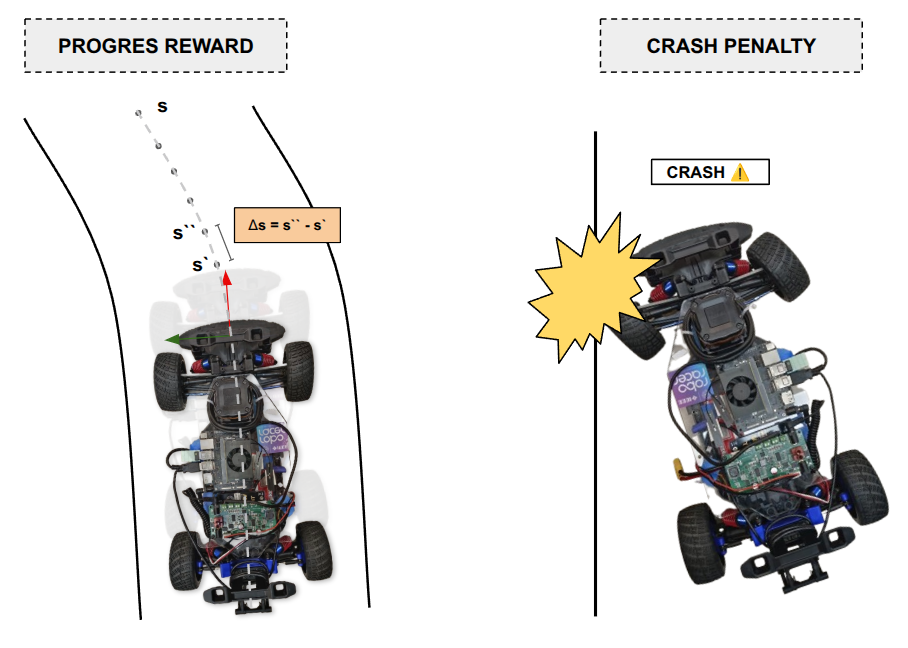

### Why These Scales?

| Term | Typical Value per Step | Purpose |
|---|---|---|
| `delta_progress × 10` | +0.01 to +0.05 | Main signal — move forward along the track |
| `0.03 × (v/vmax)` | +0.005 to +0.03 | Prevent the car learning to crawl slowly |
| Crash penalty | −30.0 (once, terminal) | Strong signal to avoid walls |

The speed bonus is kept **much smaller** than the progress signal. If it were too large, the car would learn to drive fast into walls — high speed reward minus one crash penalty might still be net positive. The relative scale between reward terms matters as much as the terms themselves.

`You can also try training without the small speed reward to start with.`

### What Will Go Wrong?

With this simple reward, the car will:
- ✅ Learn to drive forward without crashing (most of the time)
- ⚠️ Drive with a slightly wobbly steering pattern — because we never penalized jerky inputs
- ⚠️ Hug walls on corners — because getting close to a wall has no cost, only hitting it does
- ⚠️ No special signal for completing a full lap — same reward whether it finishes or stops at 99%

We will fix all of these in Part 2 with reward shaping. For now, let's get a simple version running.

> 💡 **Try this after training:** Change `crash_penalty = -5.0` and retrain. What happens to the driving behavior? Does the car take more risks?


---

# **Section 5 — Building PPO from Scratch**

## 5.1 What We're Building — PPO in Three Pieces

PPO (Proximal Policy Optimization) learns a **policy** $\pi_\theta(a \mid s)$ — a
probability distribution over actions given a state — and a **value function**
$V_\phi(s)$ that estimates expected future reward from that state. Both are
represented by one neural network in this notebook.

**1. Actor-Critic Network (TODO 5)**

For continuous actions (steering, speed), the actor outputs the mean
$\mu_\theta(s)$ of a Gaussian; a learned standard deviation $\sigma$ gives the
exploration spread:

$$a \sim \mathcal{N}\big(\mu_\theta(s),\, \sigma^2\big)$$

The critic outputs a scalar $V_\phi(s)$ — "how good is this state, roughly?"

**2. Generalized Advantage Estimation — GAE (TODO 6)**

Raw rewards are noisy. GAE converts a trajectory of rewards into a smoothed
**advantage** $A_t$ — how much better an action was than the critic expected:

$$\delta_t = r_t + \gamma\, V(s_{t+1}) - V(s_t) \qquad \text{(one-step surprise)}$$

$$A_t = \delta_t + (\gamma\lambda)\,\delta_{t+1} + (\gamma\lambda)^2\,\delta_{t+2} + \cdots \qquad \text{(blended over the trajectory)}$$

**3. Clipped Surrogate Objective (TODO 7)**

The update rule that increases the probability of actions with positive
advantage — but *clips* the change so the policy never moves too far in one
step, which is what makes PPO stable compared to plain policy gradient:

$$r_t(\theta) = \frac{\pi_\theta(a_t \mid s_t)}{\pi_{\theta_{\text{old}}}(a_t \mid s_t)}$$

$$L^{CLIP}(\theta) = \mathbb{E}_t\Big[\min\big(r_t(\theta)\,A_t,\ \text{clip}(r_t(\theta),\,1-\epsilon,\,1+\epsilon)\,A_t\big)\Big]$$

Everything else in this notebook — the environment, the reward, and evaluation —
is the same regardless of which algorithm learns from it. Only the learning
algorithm below is something you build by hand.

## 5.2 Imports


In [ ]:
# ── Imports for from-scratch PPO ──────────────────────────────────────────────
import os
import copy
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Normal

# Vectorized environment utilities — run several simulators in parallel and
# normalize rewards for stable gradients. The PPO algorithm itself is ours,
# built from scratch in the sections below.
from stable_baselines3.common.vec_env import (
    SubprocVecEnv, DummyVecEnv, VecMonitor, VecNormalize
)

print('PyTorch version:', torch.__version__)
print('Modules imported — we build PPO ourselves below.')


PyTorch version: 2.11.0+cu128
Modules imported — we build PPO ourselves below.


## 5.3 Training Configuration

> 🔧 **IMPORTANT - These are the values you can change to experiment.**

In [ ]:
# ── Training configuration ────────────────────────────────────────────────────
# Change these to experiment!

MAP_NAME    = "Spielberg"   # Track to train on
NUM_ENVS    = 4             # Parallel environments
TOTAL_STEPS = 1_000_000     # Total training steps (~30 min on T4 GPU)
DEVICE      = "cuda"        # Use GPU — much faster for rollout collection

print(f"Training config:")
print(f"  Map:    {MAP_NAME}")
print(f"  Envs:   {NUM_ENVS}")
print(f"  Steps:  {TOTAL_STEPS:,}")
print(f"  Device: {DEVICE}")

Training config:
  Map:    Spielberg
  Envs:   4
  Steps:  1,000,000
  Device: cuda


## 5.4 WandB Login

_WandB is a free tool that will give us a live dashboard for tracking our training runs. It logs our training metrics like reward, collisions, and speed, so we can watch your car improve in real time, easily compare different experiments, and quickly figure out what reward settings actually work._

You will need a free account at [wandb.ai](https://wandb.ai) — it takes 30 seconds to sign up.

After running this cell, click the link it prints to see your live dashboard.

> **Get your API key at:** [wandb.ai/authorize](https://wandb.ai/authorize)

In [ ]:
# ── WandB login ───────────────────────────────────────────────────────────────

# Choose option 1 or 2, then paste your WANDB_API key
wandb.login()

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
/usr/local/lib/python3.13/dist-packages/notebook/utils.py:280: DeprecationWarning: distutils Version classes are deprecated. Use packaging.version instead.
  return LooseVersion(v) >= LooseVersion(check)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: 1


wandb: You chose 'Create a W&B account'
wandb: Create an account here: https://wandb.ai/authorize?signup=true&ref=models
wandb: After creating your account, create a new API key and store it securely.


wandb: Paste your API key and hit enter: ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: dhyey28 (kvirmani-university-of-pennsylvania) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


True

## 5.2 The Actor-Critic Network (TODO 5)

Two **fully independent** networks — the actor and critic do **not** share any
layers. Sharing weights between them would let policy gradients and value
gradients fight over the same parameters, which hurts both objectives:

```
obs (110) → [Linear 64 + Tanh] → [Linear 64 + Tanh] → actor features  → μ(s)  (2 numbers: mean steer, mean speed)
obs (110) → [Linear 64 + Tanh] → [Linear 64 + Tanh] → critic features → V(s)  (1 number: value estimate)
```

**Actor math:** the head outputs $\mu = \text{actor\_mean}(\text{actor}(obs)) \in \mathbb{R}^2$.
Combined with a learnable, state-independent $\log\sigma$, this defines a
Gaussian policy:

$$\pi_\theta(a \mid s) = \mathcal{N}\big(a;\ \mu(s),\, \sigma^2\big)$$

- **Training** (exploration): sample $a \sim \mathcal{N}(\mu, \sigma)$ — randomness lets the agent try things
- **Evaluation** (deterministic): take $a = \mu$ — the network's best guess, no randomness

**Critic math:** $V(s) = \text{critic}(\text{critic\_body}(obs))$ is trained to
predict the discounted sum of future rewards from state $s$ — this is the
baseline GAE (next section) subtracts to compute advantages.

**Initialization matters more than you'd think:** we use orthogonal
initialization with a *small* gain (0.01) specifically on the action output
layer. This keeps the policy's initial actions close to zero — a large random
initial policy can send the car into a wall on step one, before it's learned
anything, wasting early experience on garbage transitions.

In [ ]:
# ── Actor-Critic Network ──────────────────────────────────────────────────────
# Two INDEPENDENT [64,64] MLPs — no shared trunk. Sharing weights between the
# actor and critic would let policy gradients and value gradients interfere
# with the same parameters, hurting both objectives. Orthogonal
# initialization with a small gain on the action head keeps initial actions
# near zero, which is important for early training stability.

def _orthogonal_init(layer, gain):
    nn.init.orthogonal_(layer.weight, gain=gain)
    nn.init.constant_(layer.bias, 0.0)

class ActorCritic(nn.Module):
    def __init__(self, obs_dim, act_dim, hidden=64):
        super().__init__()
        # Actor — fully independent MLP, own weights
        self.actor = nn.Sequential(
            nn.Linear(obs_dim, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden),  nn.Tanh(),
        )
        self.actor_mean = nn.Linear(hidden, act_dim)

        # Critic — fully independent MLP, own weights (no sharing with the actor)
        self.critic_body = nn.Sequential(
            nn.Linear(obs_dim, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden),  nn.Tanh(),
        )
        self.critic = nn.Linear(hidden, 1)

        # Learnable log standard deviation (state-independent)
        self.log_std = nn.Parameter(torch.zeros(act_dim))

        # Orthogonal init gains: sqrt(2) for hidden layers, 0.01 for the
        # action output (near-zero initial actions), 1.0 for the value output
        for layer in self.actor:
            if isinstance(layer, nn.Linear): _orthogonal_init(layer, gain=2 ** 0.5)
        for layer in self.critic_body:
            if isinstance(layer, nn.Linear): _orthogonal_init(layer, gain=2 ** 0.5)
        _orthogonal_init(self.actor_mean, gain=0.01)
        _orthogonal_init(self.critic, gain=1.0)

    def forward(self, obs):
        # ═══════════════════════════════════════════════════════════════
        #  TODO 5 — Actor-Critic Forward Pass
        # ═══════════════════════════════════════════════════════════════
        # Compute the mean, value, std, dist and return the dist, value
        #   mean       = self.actor_mean(self.actor(obs))
        #   value      = self.critic(self.critic_body(obs)).squeeze(-1)
        #   std        = self.log_std.exp()  (broadcast to mean's shape)
        #   dist       = Normal(mean, std)
        # Return: dist, value
        # ───────────────────────────────────────────────────────────────







        # ═══════════════════════════════════════════════════════════════

    @torch.no_grad()
    def act(self, obs, deterministic=False):
        """Sample an action (or take the mean if deterministic)."""
        dist, value = self.forward(obs)
        action = dist.mean if deterministic else dist.sample()
        log_prob = dist.log_prob(action).sum(-1)
        return action, log_prob, value


print('ActorCritic network defined (separate actor/critic MLPs, orthogonal init).')


ActorCritic network defined (separate actor/critic MLPs, SB3-matching init).


## 5.4 Environment Builders

In [ ]:
# ── Environment factory ───────────────────────────────────────────────────────
# SubprocVecEnv needs a list of functions that each create one environment —
# this factory pattern lets each parallel worker build its own independent
# environment instance.

def make_env(map_name, rank, seed=0):
    """Returns a function that creates one F1TenthRLWrapper instance."""
    def _init():
        env = F1TenthRLWrapper(map_name=map_name)
        env.reset(seed=seed + rank)   # different seed per env = diverse experience
        return env
    return _init


def make_training_env(map_name, num_envs):
    """
    Creates the vectorized training environment.
    Wrapper order matters — VecNormalize MUST be outermost.
    """
    if num_envs == 1:
        env = DummyVecEnv([make_env(map_name, 0)])       # single env, no subprocess
    else:
        env = SubprocVecEnv([make_env(map_name, i) for i in range(num_envs)])
    env = VecMonitor(env)      # adds episode reward/length logging
    env = VecNormalize(        # normalizes rewards - outermost
        env,
        norm_obs    = False,   # lidar already in [0,1] — don't normalize again
        norm_reward = True,    # normalize rewards for stable gradients
        clip_reward = 10.0,
        gamma       = 0.99,
    )
    return env


def make_eval_env(map_name):
    """
    Creates the evaluation environment.
    Same wrapper order, but training=False freezes normalization stats.
    """
    env = DummyVecEnv([make_env(map_name, 99)])
    env = VecMonitor(env)
    env = VecNormalize(
        env,
        norm_obs    = False,
        norm_reward = True,
        clip_reward = 10.0,
        gamma       = 0.99,
        training    = False,   # freeze stats — don't update during eval
    )
    return env


print("Environment builders defined successfully.")

Environment builders defined successfully.


---

# **Section 6 — The PPO Algorithm**

## 6.1 GAE — Generalized Advantage Estimation (TODO 6)

After collecting a batch of experience, we need to score how good each action
was — not just the raw reward, but relative to what the critic *expected*.
That relative score is called the **advantage** $A_t$.

Two parameters control the estimate:

- **$\gamma$ (gamma)** — discount factor: how much future reward matters (0.99 = a lot)
- **$\lambda$ (lambda)** — GAE smoothing: blends short-horizon (low variance, biased)
  and long-horizon (unbiased, high variance) advantage estimates

The advantage is computed backwards through the trajectory, one step at a time:

$$\delta_t = r_t + \gamma\, V(s_{t+1})\,(1 - d_t) - V(s_t) \qquad \text{TD residual — was this step a surprise?}$$

$$A_t = \delta_t + \gamma\lambda\,(1 - d_t)\,A_{t+1} \qquad \text{GAE recursion — blend with the future}$$

where $d_t \in \{0, 1\}$ marks whether the episode ended at step $t$.

The **return** (the target the critic trains toward) is then simply:

$$R_t = A_t + V(s_t)$$

In [ ]:
# ── GAE — Generalized Advantage Estimation ────────────────────────────────────
def compute_gae(rewards, values, dones, last_value, gamma=0.99, lam=0.95):
    """
    rewards, values, dones : tensors of shape (T, N)  [T steps, N envs]
    last_value             : tensor (N,) — V(s_T) for bootstrapping
    Returns advantages and returns, both (T, N).
    """
    T, N = rewards.shape
    advantages = torch.zeros_like(rewards)

    # ═══════════════════════════════════════════════════════════════
    # TODO 6 — Compute GAE Advantages
    # ═══════════════════════════════════════════════════════════════
    #At each step, take the next value (last value if at the end,
    #otherwise the next stored one).
    #Discount it only if the next state isn't terminal.
    #Compute the TD residual: reward plus discounted next value minus
    #current value.
    #Accumulate GAE by adding the discounted, decayed previous advantage.
    #Store it and move to the previous step.
    # ───────────────────────────────────────────────────────────────
    last_adv = torch.zeros(N, device=rewards.device)








    # ═══════════════════════════════════════════════════════════════

    returns = advantages + values
    return advantages, returns


print('compute_gae defined.')


compute_gae defined.


---

## 6.2 A Note on Hyperparameter Sweeps *(Preview — Not in This Notebook)*

You just hand-picked values like `GAMMA`, `CLIP_EPS`, `ENT_COEF`, and `LR` in the
training cell below. In practice these are rarely obvious — a small change in
`ent_coef` or `clip_eps` can be the difference between a policy that converges
and one that never does.

**WandB Sweeps** automate this search: you define a range for each
hyperparameter, and WandB launches many short training runs, logging every
result to a dashboard where you can compare them side by side (e.g. a parallel
coordinates plot showing which combinations produced the best reward).

We are **not** implementing a sweep in this notebook — hand-tuned values are
enough to get a working policy. **Part 2** of this course introduces WandB
Sweeps properly, so you can search reward-shaping coefficients automatically
instead of guessing.

---

# **Section 7 — Training**

## 7.1 The PPO Loss and Training Loop

The training loop repeats:
1. **Collect** `n_steps` of experience from all parallel envs
2. **Compute** advantages with GAE (TODO 6)
3. **Update** the network for several epochs using the clipped PPO loss (TODO 7)

**The clipped surrogate objective (TODO 7)** is the core of PPO. Define the
probability ratio between the new and old policy for the action actually taken:

$$r_t(\theta) = \frac{\pi_\theta(a_t \mid s_t)}{\pi_{\theta_{\text{old}}}(a_t \mid s_t)}$$

Then the loss is:

$$\text{surr}_1 = r_t(\theta)\, A_t$$

$$\text{surr}_2 = \text{clip}\big(r_t(\theta),\, 1-\epsilon,\, 1+\epsilon\big)\, A_t$$

$$L^{\text{policy}} = -\mathbb{E}_t\big[\min(\text{surr}_1,\, \text{surr}_2)\big]$$

Without the clip, a single large advantage could push $r_t(\theta)$ far from 1,
causing a destructively large policy update. The $\min(\cdot,\cdot)$ with the
clipped version caps how much credit the update can take for a good ratio —
this is what makes PPO stable where plain policy gradient is not.

**Total loss** combines three terms:

$$L = L^{\text{policy}} + c_1\, L^{\text{value}} - c_2\, \mathcal{H}[\pi_\theta]$$

- $L^{\text{value}} = \big(V_\phi(s_t) - R_t\big)^2$ — MSE between the critic's prediction and the GAE return
- $\mathcal{H}[\pi_\theta]$ (entropy of the Gaussian) is *subtracted* — maximizing it keeps
  the policy exploring rather than collapsing to a single action too early

In [ ]:
# ── Live Inline Training Plots ────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from IPython.display import clear_output

_live = {"steps": [], "rew": [], "collision": [], "speed": [], "laps": [], "loss": []}

def draw_live_plots(total_steps):
    if len(_live['steps']) < 2:
        return
    BG = '#0d1117'
    fig = plt.figure(figsize=(14, 6), facecolor=BG)
    gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.5, wspace=0.35)
    plots = [
        (gs[0,0], _live['rew'],       'ep_reward ↑',           '#00bcd4'),
        (gs[0,1], _live['collision'], 'collision_rate ↓',      '#f44336'),
        (gs[0,2], _live['speed'],     'avg_speed m/s ↑',       '#69ff47'),
        (gs[1,0], _live['laps'],      'lap_completion_rate ↑', '#ff9800'),
        (gs[1,1], _live['loss'],      'total_loss',            '#e91e63'),
    ]
    for spec, data, title, color in plots:
        ax = fig.add_subplot(spec)
        ax.set_facecolor('#1a1a2e')
        valid = [(s, v) for s, v in zip(_live['steps'], data) if v is not None]
        if valid:
            xs, ys = zip(*valid)
            ax.plot(xs, ys, color=color, lw=2, marker='o', markersize=3)
            ax.fill_between(xs, ys, alpha=0.15, color=color)
            lo, hi = min(ys), max(ys); pad = (hi-lo)*0.1 or 0.1
            ax.set_ylim(lo-pad, hi+pad)
        ax.set_title(title, color='white', fontsize=9, pad=4)
        ax.set_xlabel('Steps', color='#888', fontsize=7)
        ax.tick_params(colors='#888', labelsize=7)
        for spine in ax.spines.values(): spine.set_edgecolor('#333')
    step = _live['steps'][-1]
    pct  = step / total_steps * 100
    wandb_url = wandb.run.url if wandb.run else 'not connected'
    fig.suptitle(f'PPO from Scratch  |  Step {step:,} / {total_steps:,}  ({pct:.1f}%)'
                 f'   |   WandB → {wandb_url}',
                 color='white', fontsize=9, x=0.02, ha='left')
    clear_output(wait=True)
    plt.show()
    plt.close(fig)

print('Live plot helper defined.')


Live plot helper defined.


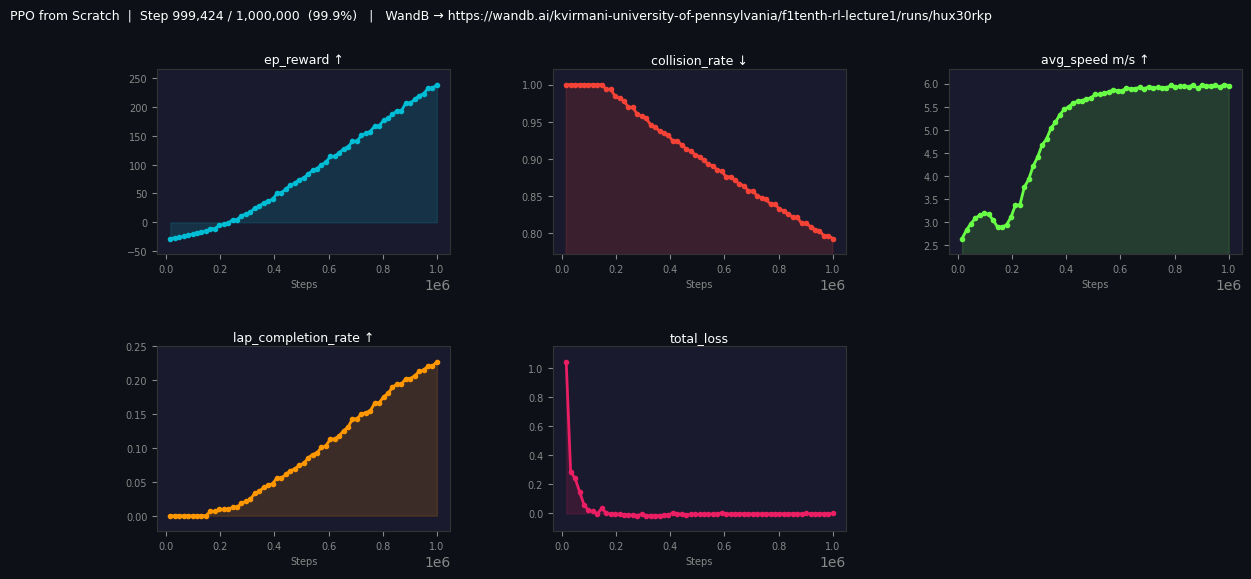

Update 61/61 | step 999,424 | episodes=400 | ep_rew_mean=239.0 | collision_rate=0.79 | lap_rate=0.23 | loss=0.0003

Saved → models_scratch/ppo_scratch.pt
Saved → models_scratch/vecnormalize.pkl


eval/mean_ep_length,▁██████▆███████
eval/mean_reward,▁▃▃▄▆▆▇▆▇▇▇████
global_step,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▂▃▃▃▄▅▅▅▅█
racing/avg_min_scan,▁▄▄▁▆▅▂▃▅▃▃▇▇▆▅▆▆▇▆▃▆▆▅▅▄▅▅▃▆▅▅█▇▆▆▆▇▇▇█
racing/avg_speed,▁▃▃▃▃▃▂▃▂▂▃▁▂▃▂▄▃▃▃▃▃▃▃▃▂▄▃▄▃▃▃▄▇▇▇█████
racing/collision_rate,██████████████████████████████████▇▆▅▄▄▁
racing/episode_count,▁▁▁▁▁▂▂▂▂▂▂▃▃▃▃▄▄▄▅▅▅▆▆▆▆▆▆▆▆▆▇▇▇▇▇█████
racing/lap_completion_rate,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▃▄▆▆▇█
racing/track_progress,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▂▁▁▁▁▁▁▂▁▃███▁▆▆▇▇▇
rollout/ep_len_mean,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▂▄▄▅▆▆▆▇█
+8,...


In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
#  PPO from Scratch — Training (Run This Single Cell)
# ══════════════════════════════════════════════════════════════════════════════
# Collects rollouts → computes GAE → updates with the clipped PPO loss.


# TODO 7 (the clipped surrogate objective) is inside the update loop.
#
# Metric definitions:
#   - collision_rate / lap_completion_rate = CUMULATIVE totals since training
#     started (never reset), not a moving window
#   - avg_speed / avg_min_scan            = averaged over the ONE episode that
#     just ended, logged the instant that episode completes
#   - rollout/ep_rew_mean / ep_len_mean   = rolling mean over the last 100
#     completed episodes
#   - train/* metrics                     = averaged over all minibatches in
#     the update
#   - eval/*                              = periodic deterministic evaluation
#     on a separate env
# ──────────────────────────────────────────────────────────────────────────────
from collections import deque

# ── Hyperparameters ───────────────────────────────────────────────────────────
N_STEPS       = 4096          # steps collected per env per update
N_EPOCHS      = 10            # optimization epochs per update
MINIBATCH     = 256
GAMMA         = 0.99
GAE_LAMBDA    = 0.95
CLIP_EPS      = 0.2           # PPO clip range ε
ENT_COEF      = 0.001         # entropy bonus
VF_COEF       = 0.5           # value loss weight
LR            = 3e-4
MAX_GRAD      = 0.5
EVAL_FREQ     = 50_000        # how often (in env steps) to run a deterministic eval pass
EVAL_EPISODES = 5

# ── Seed everything — for reproducible runs ───────────────────────────────────
torch.manual_seed(42)
np.random.seed(42)

# ── Initialize WandB ──────────────────────────────────────────────────────────
run = wandb.init(
    project = 'f1tenth-rl-lecture1',
    name    = f'ppo_scratch_{MAP_NAME}_{TOTAL_STEPS//1000}k',
    config  = dict(n_steps=N_STEPS, n_epochs=N_EPOCHS, gamma=GAMMA,
                   gae_lambda=GAE_LAMBDA, clip_eps=CLIP_EPS, ent_coef=ENT_COEF,
                   lr=LR, map=MAP_NAME, num_envs=NUM_ENVS),
)
# Force WandB to use real environment steps as the x-axis for EVERY metric,
# instead of its default behavior of incrementing once per wandb.log() call.
# Without this, racing/* (logged per episode) and train/* (logged per update)
# get squeezed onto a shared call-counter whose scale depends on how many
# episodes completed — which differs hugely between runs and makes two
# training runs visually incomparable even when the underlying training
# is identical.
wandb.define_metric('global_step')
wandb.define_metric('*', step_metric='global_step')

print(f'🔗 WandB → {run.url}\n')

# ── Create envs (parallel rollouts + reward normalization) ───────────────────
train_env = make_training_env(MAP_NAME, NUM_ENVS)
eval_env  = make_eval_env(MAP_NAME)   # separate env for periodic deterministic eval
obs_dim   = train_env.observation_space.shape[0]
act_dim   = train_env.action_space.shape[0]

# ── Build network + optimizer ─────────────────────────────────────────────────
device = torch.device(DEVICE if torch.cuda.is_available() else 'cpu')
net    = ActorCritic(obs_dim, act_dim).to(device)
opt    = optim.Adam(net.parameters(), lr=LR, eps=1e-5)   # eps=1e-5 for numerical stability
print(net)
print(f'Parameters: {sum(p.numel() for p in net.parameters()):,}\n')

# ── Metric tracking ───────────────────────────────────────────────────────────
episode_count    = 0     # cumulative — never reset
total_collisions = 0     # cumulative — never reset
total_laps       = 0     # cumulative — never reset

cur_rew  = np.zeros(NUM_ENVS)                 # per-episode accumulators
cur_spd  = [[] for _ in range(NUM_ENVS)]      # reset after each episode ends
cur_scan = [[] for _ in range(NUM_ENVS)]
cur_col      = np.zeros(NUM_ENVS, dtype=bool)
cur_lap      = np.zeros(NUM_ENVS, dtype=int)
cur_len      = np.zeros(NUM_ENVS, dtype=int)
cur_progress = np.zeros(NUM_ENVS)   # overwritten every step with the current episode's progress

ep_rew_window = deque(maxlen=100)   # rolling 100-episode window
ep_len_window = deque(maxlen=100)

_live.update({k: [] for k in _live})
update_speeds = []   # for the local inline plot only — all speeds seen this update

obs = train_env.reset()
obs = torch.tensor(obs, dtype=torch.float32, device=device)
global_step    = 0
last_eval_step = 0
n_updates      = TOTAL_STEPS // (N_STEPS * NUM_ENVS)

print(f'Training {TOTAL_STEPS:,} steps = {n_updates} updates — plots update below\n')

for update in range(n_updates):
    # ── 1. Collect rollout ────────────────────────────────────────────────────
    mb_obs, mb_act, mb_logp, mb_val, mb_rew, mb_done = [], [], [], [], [], []
    update_speeds = []

    for _ in range(N_STEPS):
        action, logp, value = net.act(obs)
        act_np = action.cpu().numpy()
        # The Gaussian sample can fall outside [-1, 1] even though that's the
        # valid action range — clip before stepping the env, but keep the
        # UNCLIPPED action for the log-prob used in the PPO update below.
        clipped_np = np.clip(act_np, -1.0, 1.0)
        next_obs, reward, dones, infos = train_env.step(clipped_np)

        # VecNormalize (outermost) returns the NORMALIZED reward, which is what
        # we train on. For episode reward TRACKING, we want the RAW reward
        # instead — pulled from VecMonitor, which sits before VecNormalize.
        raw_reward = train_env.get_original_reward()

        mb_obs.append(obs)
        mb_act.append(action)
        mb_logp.append(logp)
        mb_val.append(value)
        mb_rew.append(torch.tensor(reward, dtype=torch.float32, device=device))
        mb_done.append(torch.tensor(dones, dtype=torch.float32, device=device))

        cur_rew += raw_reward
        cur_len += 1
        for i, inf in enumerate(infos):
            spd = inf.get('speed', 0.0)
            cur_spd[i].append(spd)
            cur_scan[i].append(inf.get('min_scan', 0.0))
            update_speeds.append(spd)
            if 'progress' in inf: cur_progress[i] = inf['progress']
            if inf.get('collision', False): cur_col[i] = True
            if inf.get('lap_completed', False): cur_lap[i] += 1

        # ── Bootstrap truncated (not crashed) episodes before GAE ─────────────
        # A "done" from hitting max_steps is a TRUNCATION, not a real terminal
        # state — the car was still driving fine, just cut off arbitrarily.
        # Add gamma*V(terminal_obs) back onto the reward at that step so GAE
        # doesn't treat it like the value of the future is zero. Skipping this
        # destabilizes the value function once episodes start surviving to
        # the step cap (visible as explained_variance collapsing).
        for i, d in enumerate(dones):
            if d and infos[i].get('TimeLimit.truncated', False):
                term_obs = torch.tensor(
                    infos[i]['terminal_observation'], dtype=torch.float32, device=device
                ).unsqueeze(0)
                with torch.no_grad():
                    _, term_value = net(term_obs)
                mb_rew[-1][i] += GAMMA * term_value.item()

        # ── Log per-episode metrics the INSTANT each episode ends ─────────────
        # collision_rate/lap_rate are cumulative-since-start;
        # avg_speed/avg_min_scan are that one episode's average
        for i, d in enumerate(dones):
            if d:
                episode_count    += 1
                total_collisions += int(cur_col[i])
                total_laps       += cur_lap[i]
                ep_rew_window.append(cur_rew[i])
                ep_len_window.append(cur_len[i])

                wandb.log({
                    'racing/avg_speed':           float(np.mean(cur_spd[i]))  if cur_spd[i]  else 0.0,
                    'racing/avg_min_scan':        float(np.mean(cur_scan[i])) if cur_scan[i] else 0.0,
                    'racing/track_progress':      float(cur_progress[i]),
                    'racing/collision_rate':      total_collisions / episode_count,
                    'racing/lap_completion_rate': total_laps / episode_count,
                    'racing/episode_count':       episode_count,
                    'rollout/ep_rew_mean':        float(np.mean(ep_rew_window)),
                    'rollout/ep_len_mean':        float(np.mean(ep_len_window)),
                    'rollout/ep_len_std':         float(np.std(ep_len_window)) if len(ep_len_window) > 1 else 0.0,
                    'global_step':                global_step,
                })

                cur_rew[i] = 0.0; cur_spd[i] = []; cur_scan[i] = []
                cur_col[i] = False; cur_lap[i] = 0; cur_len[i] = 0

        obs = torch.tensor(next_obs, dtype=torch.float32, device=device)
        global_step += NUM_ENVS

    # ── 2. Compute GAE (TODO 6) ───────────────────────────────────────────────
    with torch.no_grad():
        _, last_value = net(obs)
    rewards = torch.stack(mb_rew)
    values  = torch.stack(mb_val)
    dones_t = torch.stack(mb_done)
    advantages, returns = compute_gae(rewards, values, dones_t, last_value,
                                      gamma=GAMMA, lam=GAE_LAMBDA)

    # Flatten (T, N, ...) → (T*N, ...)
    b_obs     = torch.stack(mb_obs).reshape(-1, obs_dim)
    b_act     = torch.stack(mb_act).reshape(-1, act_dim)
    b_logp    = torch.stack(mb_logp).reshape(-1)
    b_adv     = advantages.reshape(-1)
    b_ret     = returns.reshape(-1)
    b_val_old = values.reshape(-1)   # pre-update value predictions — for explained_variance
    # NOTE: advantages are normalized PER MINIBATCH below, not here — a fresh
    # mean/std computed for each minibatch inside the epoch loop is a
    # different (noisier) quantity than one whole-batch normalization.

    # ── 3. PPO update epochs ──────────────────────────────────────────────────
    batch_size = b_obs.shape[0]
    idxs = np.arange(batch_size)
    epoch_losses, epoch_pg, epoch_vf, epoch_ent, epoch_clipfrac, epoch_kl = [], [], [], [], [], []
    for epoch in range(N_EPOCHS):
        np.random.shuffle(idxs)
        for start in range(0, batch_size, MINIBATCH):
            mb = idxs[start:start + MINIBATCH]
            dist, value = net(b_obs[mb])
            new_logp = dist.log_prob(b_act[mb]).sum(-1)
            entropy  = dist.entropy().sum(-1).mean()

            # Normalize advantages fresh for THIS minibatch
            mb_adv = b_adv[mb]
            mb_adv = (mb_adv - mb_adv.mean()) / (mb_adv.std() + 1e-8)

            # ═══════════════════════════════════════════════════════════════
            # TODO 7 — PPO Clipped Surrogate Loss
            # ═══════════════════════════════════════════════════════════════
            # Compute the probability ratio between new and old policies, form two surrogate
            # objectives (raw and clipped), and take the smaller one, negated so minimizing
            # it improves the policy without letting the ratio drift past the clip. Add the
            # critic's squared error against target returns, and subtract a weighted entropy
            # bonus to keep exploration alive.
            # ───────────────────────────────────────────────────────────────






            # ═══════════════════════════════════════════════════════════════

            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(net.parameters(), MAX_GRAD)
            opt.step()

            epoch_losses.append(loss.item())
            epoch_pg.append(policy_loss.item())
            epoch_vf.append(value_loss.item())

            # Extra diagnostics SB3 logs automatically — computed by hand here
            epoch_ent.append(entropy.item())
            # clip_fraction: fraction of samples where the ratio actually got clipped
            with torch.no_grad():
                clip_frac = (torch.abs(ratio - 1.0) > CLIP_EPS).float().mean().item()
            epoch_clipfrac.append(clip_frac)
            # cheaper and lower-variance than a naive KL, computed from log-ratio only
            with torch.no_grad():
                log_ratio = new_logp - b_logp[mb]
                approx_kl = torch.mean((torch.exp(log_ratio) - 1) - log_ratio).item()
            epoch_kl.append(approx_kl)

    # ── 4. train/* metrics — averaged over the whole update ───────────────────
    y_true = b_ret.cpu().numpy()
    y_pred = b_val_old.cpu().numpy()
    var_y  = np.var(y_true)
    explained_var = float('nan') if var_y == 0 else 1.0 - np.var(y_true - y_pred) / var_y
    current_std   = net.log_std.exp().mean().item()

    wandb.log({
        'train/loss':                 float(np.mean(epoch_losses)),
        'train/policy_gradient_loss': float(np.mean(epoch_pg)),
        'train/value_loss':           float(np.mean(epoch_vf)),
        'train/std':                  current_std,
        'train/explained_variance':   explained_var,
        'train/learning_rate':        LR,
        'train/entropy_loss':         -float(np.mean(epoch_ent)),   # negative entropy, matches SB3's sign
        'train/clip_range':           CLIP_EPS,                     # constant here (no schedule)
        'train/clip_fraction':        float(np.mean(epoch_clipfrac)),
        'train/approx_kl':            float(np.mean(epoch_kl)),
        'global_step':                global_step,
    })

    # ── 5. Periodic evaluation ─────────────────────────────────────────────────
    if global_step - last_eval_step >= EVAL_FREQ:
        last_eval_step = global_step

        # Sync eval_env's VecNormalize running stats from train_env. Without
        # this, eval_env's reward normalization stays frozen at its untouched
        # initial defaults forever, so eval/mean_reward ends up on a totally
        # different scale than training's reward. Only ret_rms exists here —
        # our wrapper uses norm_obs=False, so VecNormalize never creates
        # obs_rms at all (nothing to sync there).
        eval_env.ret_rms = copy.deepcopy(train_env.ret_rms)

        eval_rewards, eval_lens = [], []
        for _ in range(EVAL_EPISODES):
            eobs = eval_env.reset()
            edone, erew, elen = False, 0.0, 0
            while not edone:
                eobs_t = torch.tensor(eobs, dtype=torch.float32, device=device)
                with torch.no_grad():
                    eaction, _, _ = net.act(eobs_t, deterministic=True)
                eobs, ereward, edones, _ = eval_env.step(eaction.cpu().numpy())
                erew += float(ereward[0]); elen += 1; edone = bool(edones[0])
            eval_rewards.append(erew); eval_lens.append(elen)
        wandb.log({
            'eval/mean_reward':    float(np.mean(eval_rewards)),
            'eval/mean_ep_length': float(np.mean(eval_lens)),
            'global_step':         global_step,
        })
        print(f'  [eval @ {global_step:,}] reward={np.mean(eval_rewards):.1f} '
              f'ep_len={np.mean(eval_lens):.0f}')

    # ── 6. Live inline plot (local only — not wandb) ──────────────────────────
    if episode_count > 0:
        _live['steps'].append(global_step)
        _live['rew'].append(float(np.mean(ep_rew_window)))
        _live['collision'].append(total_collisions / episode_count)
        _live['speed'].append(float(np.mean(update_speeds)) if update_speeds else 0.0)
        _live['laps'].append(total_laps / episode_count)
        _live['loss'].append(float(np.mean(epoch_losses)))
        draw_live_plots(TOTAL_STEPS)
        print(f'Update {update+1}/{n_updates} | step {global_step:,} | episodes={episode_count} | '
              f'ep_rew_mean={np.mean(ep_rew_window):.1f} | collision_rate={total_collisions/episode_count:.2f} | '
              f'lap_rate={total_laps/episode_count:.2f} | loss={np.mean(epoch_losses):.4f}')

# ── Save ──────────────────────────────────────────────────────────────────────
os.makedirs('models_scratch', exist_ok=True)
torch.save(net.state_dict(), 'models_scratch/ppo_scratch.pt')
train_env.save('models_scratch/vecnormalize.pkl')
print('\nSaved → models_scratch/ppo_scratch.pt')
print('Saved → models_scratch/vecnormalize.pkl')
wandb.finish()
train_env.close()
eval_env.close()


## 7.2 Save Your Trained Models

Run the cell below to download all your saved models as a single zip file.

The archive includes:
- `models/best/best_model.zip` — best policy found during training
- `models/ppo_part1_final.zip` — final model at end of training  
- `models/vecnormalize.pkl` — reward normalization stats (**required** alongside any model file to run eval correctly)
- `models/checkpoints/` — snapshots saved every 100k steps

> **Running locally:** If you have the F1TENTH gym and virtual environment set up on your local machine, downloading this model archive will let you run the trained model eval locally to see the car driving with a live render window.
_**However, for this version, we will save a headless recording directly in the notebook using rgb_array rendering, so you can visualize your results without any local setup required.**_

> _It will also be useful for the actual deployement on the car which we shall cover in the notebooks later._

In [ ]:
!zip -r models_archive.zip /content/models_scratch

updating: content/models/ (stored 0%)
updating: content/models/vecnormalize.pkl (deflated 43%)
updating: content/models/best/ (stored 0%)
updating: content/models/best/best_model.zip (stored 0%)
updating: content/models/ppo_part1_final.zip (stored 0%)
updating: content/models/checkpoints/ (stored 0%)
updating: content/models/checkpoints/ppo_Spielberg_40000_steps.zip (stored 0%)
updating: content/models/checkpoints/ppo_Spielberg_80000_steps.zip (stored 0%)
updating: content/models/eval_logs/ (stored 0%)
updating: content/models/eval_logs/evaluations.npz (deflated 55%)


In [ ]:
# Download the .zip folder locally

from google.colab import files
files.download('models_archive.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---

# **Section 8 — Monitoring & Metrics**

## 8.1 Understanding the Training Metrics

Now that training has finished (or is running), let's understand what all those numbers mean. *Run Section 8 and compare your training metrics with these values to analyze the training quality*.

### ✅ What Healthy Training Looks Like

| Metric | What It Measures | Healthy Trend |
|---|---|---|
| `racing/collision_rate` | Fraction of episodes ending in crash | 1.0 → below 0.3 |
| `racing/avg_speed` | Average speed during episode | Rising, stable above 4 m/s |
| `racing/track_progress` | Distance traveled (0→1 per lap) | Trending toward 1.0 |
| `racing/lap_completion_rate` | Fraction completing a full lap | Rising toward 0.7+ |
| `rollout/ep_rew_mean` | Average total episode reward | Trending positive |
| `rollout/ep_len_std` | Std of episode lengths | Decreasing = more consistent |
| `train/std` | Policy action randomness | Stable, not rising |
| `train/explained_variance` | Value function accuracy | Trending toward 0.8+ |
| `perf/fps_per_env` | Simulator speed per env | Should be ~500–1000 |

### ⚠️ Warning Signs

| Warning Sign | What It Means | What To Do |
|---|---|---|
| `train/std` keeps rising | Policy becoming more random | Lower `ent_coef` |
| `avg_speed` drops toward 0 | Car learned to crawl slowly | Add speed reward |
| `collision_rate` plateaus above 0.5 | Not learning fast enough | More steps, or tune LR |
| `explained_variance` stays near 0 | Value function not fitting | Check reward scale |
| `ep_len_std` very high | Inconsistent policy | More training needed |

---

# **Section 9 — Evaluation**

## 9.1 Evaluate the Trained Policy

Training is done. Let's see how well the policy actually drives.

In [ ]:
# ── Load and evaluate (our from-scratch policy) ───────────────────────────────
# Rebuild the network and load weights
eval_net = ActorCritic(obs_dim, act_dim).to('cpu')
eval_net.load_state_dict(torch.load('models_scratch/ppo_scratch.pt', map_location='cpu'))
eval_net.eval()
print('Loaded models_scratch/ppo_scratch.pt')

# Wrap a single eval env with the saved normalization stats
raw_eval = DummyVecEnv([lambda: F1TenthRLWrapper(map_name=MAP_NAME)])
raw_eval = VecMonitor(raw_eval)
eval_venv = VecNormalize.load('models_scratch/vecnormalize.pkl', raw_eval)
eval_venv.training = False
eval_venv.norm_reward = False

NUM_EVAL_EPISODES = 5
all_rewards, all_speeds, all_progress, all_laps = [], [], [], []
print(f'\nRunning {NUM_EVAL_EPISODES} evaluation episodes...')
print('─' * 65)

for ep in range(NUM_EVAL_EPISODES):
    obs = eval_venv.reset()
    total_reward, done, steps, speeds, laps = 0.0, False, 0, [], 0
    while not done:
        obs_t = torch.tensor(obs, dtype=torch.float32)
        with torch.no_grad():
            action, _, _ = eval_net.act(obs_t, deterministic=True)
        obs, reward, dones, infos = eval_venv.step(action.numpy())
        total_reward += reward[0]; done = dones[0]; steps += 1
        speeds.append(infos[0].get('speed', 0.0))
        if infos[0].get('lap_completed', False): laps += 1

    avg_spd  = np.mean(speeds)
    progress = infos[0].get('progress', 0)
    crashed  = infos[0].get('collision', False)
    all_rewards.append(total_reward); all_speeds.append(avg_spd)
    all_progress.append(progress); all_laps.append(laps)
    status = 'CRASH' if crashed else ('TIMEOUT' if steps >= 10000 else 'DONE')
    print(f'  Ep {ep+1}: {status} | reward={total_reward:7.1f} | steps={steps:5d} | '
          f'speed={avg_spd:.2f} m/s | progress={progress:.3f} | laps={laps}')

print('─' * 65)
print(f'  Average reward:   {np.mean(all_rewards):.1f} ± {np.std(all_rewards):.1f}')
print(f'  Average speed:    {np.mean(all_speeds):.2f} m/s')
print(f'  Average progress: {np.mean(all_progress):.3f} (1.0 = full lap)')
print(f'  Total laps:       {sum(all_laps)}')
eval_venv.close()


Loaded models_scratch/ppo_scratch.pt


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENV] Loaded 1692 waypoints from track
[ENV] max_steer=0.4189rad | max_speed=6.0m/s

Running 5 evaluation episodes...
─────────────────────────────────────────────────────────────────
  Ep 1: TIMEOUT | reward=  412.8 | steps=10000 | speed=7.80 m/s | progress=0.291 | laps=1
  Ep 2: TIMEOUT | reward=  412.5 | steps=10000 | speed=7.79 m/s | progress=0.289 | laps=2
  Ep 3: TIMEOUT | reward=  412.9 | steps=10000 | speed=7.80 m/s | progress=0.291 | laps=1
  Ep 4: TIMEOUT | reward=  412.7 | steps=10000 | speed=7.80 m/s | progress=0.291 | laps=1
  Ep 5: TIMEOUT | reward=  412.8 | steps=10000 | speed=7.80 m/s | progress=0.293 | laps=2
─────────────────────────────────────────────────────────────────
  Average reward:   412.8 ± 0.1
  Average speed:    7.80 m/s
  Average progress: 0.291 (1.0 = full lap)
  Total laps:       7


---

## 9.2 Record Eval Video in Colab - _See your Policy in Action !_

Since our colab session has no display, we can't open a render window directly. Instead we create a fresh environment with `render_mode="rgb_array"` which returns frames as numpy arrays — no display needed. We wrap it with `DummyVecEnv` and load the saved `VecNormalize` stats so the policy sees the same observation scale it was trained on, then capture every 5th frame and save as an MP4.


In [ ]:
# ── Record eval video (our from-scratch policy) ───────────────────────────────
!pip install -q imageio imageio-ffmpeg
import imageio

vid_net = ActorCritic(obs_dim, act_dim).to('cpu')
vid_net.load_state_dict(torch.load('models_scratch/ppo_scratch.pt', map_location='cpu'))
vid_net.eval()

venv = DummyVecEnv([lambda: F1TenthRLWrapper(map_name=MAP_NAME, render_mode='rgb_array')])
venv = VecMonitor(venv)
venv = VecNormalize.load('models_scratch/vecnormalize.pkl', venv)
venv.training = False; venv.norm_reward = False

frames = []
obs = venv.reset(); done = False; step = 0
while not done and step < 5000:
    obs_t = torch.tensor(obs, dtype=torch.float32)
    with torch.no_grad():
        action, _, _ = vid_net.act(obs_t, deterministic=True)
    obs, _, dones, _ = venv.step(action.numpy())
    done = dones[0]; step += 1
    if step % 5 == 0:
        frame = venv.envs[0].render()
        if frame is not None: frames.append(frame)
venv.close()

if frames:
    print(f'✅ Captured {len(frames)} frames')
    imageio.mimsave('eval_render_scratch.mp4', frames, fps=20)
    from google.colab import files
    files.download('eval_render_scratch.mp4')
else:
    print('❌ No frames captured')


/usr/local/lib/python3.13/dist-packages/pyqtgraph/parametertree/Parameter.py:140: DeprecationWarning: Parameter has no default value. Pass a default, or use setDefault(). This will no longer set an implicit default after January 2025.
  return cls(**opts)


[ENV] Loaded 1692 waypoints from track
[ENV] max_steer=0.4189rad | max_speed=6.0m/s


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

✅ Captured 1000 frames


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---

# **Section 10 — Summary & Next Steps**

## 10.1 What We Built

In about 30 minutes of training, we went from a completely random policy that crashes immediately to a car that:
- Drives forward at 4–6 m/s (2-3 m/s without speed reward term)
- Avoids walls most of the time
- Completes full laps on the Spielberg track

All without any hand-coded rules — purely from the reward signal.

## 9.2 What's Still Wrong

If you watched the evaluation output, you probably noticed:

- **Inconsistent performance** — some episodes complete laps, some crash early
- **Squiggly steering** — no penalty for jerky inputs
- **Not necessarily fast** — the speed bonus was small, so it might take a conservative line
- **No awareness of the racing line** — the car goes forward, but not optimally

These are all reward function problems, not algorithm problems. PPO is doing its job — it's optimizing exactly what we asked it to. We just didn't ask for quite enough.

## 9.3 Exercises — Try These Before Part 2

1. **Change the crash penalty** from -30 to -5. Does the car take more risks? Does it crash more?
2. **Remove the speed reward** entirely (`reward += 0` instead of `0.03 * ...`). How does avg_speed change?
3. **Change NUM_ENVS from 4 to 1**. How much slower is training? How does it affect quality?

---

## 9.4 Saving the Model Files - IMPORTANT for local evaluation, and deployement on the car

> **💾 Saving your model:** If you want to keep the trained model, download `models/ppo_part1_final.zip` and `models/vecnormalize.pkl` from the Colab file browser on the left. You will need both files to load and run the policy later.

## 10.2 Save Models to Google Drive *(Optional)*

Colab sessions are temporary — models are lost when the session ends. Uncomment the cell below to save your model to Google Drive.

In [ ]:
# ── Optional: Save models to Google Drive ─────────────────────────────────────
# Uncomment and run this cell to save your trained model to Google Drive
#so it persists after the Colab session ends.

#from google.colab import drive
#drive.mount('/content/drive')

#import shutil
#shutil.copy('models_scratch/ppo_part1_final.zip', '/content/drive/MyDrive/')
#shutil.copy('models_scratch/vecnormalize.pkl',    '/content/drive/MyDrive/')
#shutil.copy('models_scratch/best/best_model.zip', '/content/drive/MyDrive/')
#print("Models saved to Google Drive!")

#print("Uncomment the lines above to save your model to Google Drive.")

# **Section 11 - Video Demo**

Below is sample of how your car would look in the simulation:

**🖥️ Local Render** — Full simulator visualization running on a local machine:
https://drive.google.com/file/d/1r8cnzX65qW-yqa8CoUi1e9ji8fHsQA2e/view?usp=sharing

**☁️ Colab Headless Recording** — The rgb_array capture from this notebook, no local setup required:
https://drive.google.com/file/d/1VtQlQb_8VuquyW-A9J84_nnre3fIX1P5/view?usp=sharing

# **Section 12 - Coming Up in Part 2**

> We will fix the problems above by improving the reward function:

| Problem | Part 2 Fix |
|---|---|
| Squiggly steering | Steering smoothness penalty |
| Hugging walls | Wall proximity penalty |
| No lap completion signal | Lap completion bonus (+50) |
| Slow in corners | Frenet-frame based reward |

By the end of Part 2, you will have a refined reward function that will produce smoother, faster, and more consistent driving, and cover the key techniques needed to deploy your trained policy onto the physical car for racing.